In [ ]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Load Dataset
df = pd.read_csv("student_performance.csv")

df = df.drop(columns=['OnlineCourses'])

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
df.describe()

,StudyHours,Attendance,Resources,Extracurricular,Motivation,Internet,Gender,Age,LearningStyle,Discussions,AssignmentCompletion,ExamScore,EduTech,StressLevel,FinalGrade
count,14003.000000,14003.000000,14003.000000,14003.000000,14003.000000,14003.000000,14003.000000,14003.000000,14003.000000,14003.00000,14003.000000,14003.000000,14003.000000,14003.000000,14003.000000
mean,19.987431,80.194316,1.104406,0.594158,0.905806,0.925516,0.551953,23.532172,1.515461,0.60587,74.502535,70.346926,0.709062,1.304363,1.447904
std,5.890637,11.472181,0.697362,0.491072,0.695896,0.262566,0.497311,3.514293,1.112941,0.48868,14.632177,17.688113,0.454211,0.785383,1.121550
min,5.000000,60.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.000000,0.000000,0.00000,50.000000,40.000000,0.000000,0.000000,0.000000
25%,16.000000,70.000000,1.000000,0.000000,0.000000,1.000000,0.000000,20.000000,1.000000,0.00000,62.000000,55.000000,0.000000,1.000000,0.000000
50%,20.000000,80.000000,1.000000,1.000000,1.000000,1.000000,1.000000,24.000000,2.000000,1.00000,74.000000,70.000000,1.000000,2.000000,1.000000
75%,24.000000,90.000000,2.000000,1.000000,1.000000,1.000000,1.000000,27.000000,3.000000,1.00000,87.000000,86.000000,1.000000,2.000000,2.000000
max,44.000000,100.000000,2.000000,1.000000,2.000000,1.000000,1.000000,29.000000,3.000000,1.00000,100.000000,100.000000,1.000000,2.000000,3.000000


In [ ]:
df.head()

,StudyHours,Attendance,Resources,Extracurricular,Motivation,Internet,Gender,Age,LearningStyle,Discussions,AssignmentCompletion,ExamScore,EduTech,StressLevel,FinalGrade
0,19,64,1,0,0,1,0,19,2,1,59,40,0,1,3
1,19,64,1,0,0,1,0,23,3,0,90,66,0,1,2
2,19,64,1,0,0,1,0,28,1,0,67,99,1,1,0
3,19,64,1,1,0,1,0,19,2,1,59,40,0,1,3
4,19,64,1,1,0,1,0,23,3,0,90,66,0,1,2


In [ ]:
df.columns

Index(['StudyHours', 'Attendance', 'Resources', 'Extracurricular',
       'Motivation', 'Internet', 'Gender', 'Age', 'LearningStyle',
       'Discussions', 'AssignmentCompletion', 'ExamScore', 'EduTech',
       'StressLevel', 'FinalGrade'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14003 entries, 0 to 14002
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   StudyHours            14003 non-null  int64
 1   Attendance            14003 non-null  int64
 2   Resources             14003 non-null  int64
 3   Extracurricular       14003 non-null  int64
 4   Motivation            14003 non-null  int64
 5   Internet              14003 non-null  int64
 6   Gender                14003 non-null  int64
 7   Age                   14003 non-null  int64
 8   LearningStyle         14003 non-null  int64
 9   Discussions           14003 non-null  int64
 10  AssignmentCompletion  14003 non-null  int64
 11  ExamScore             14003 non-null  int64
 12  EduTech               14003 non-null  int64
 13  StressLevel           14003 non-null  int64
 14  FinalGrade            14003 non-null  int64
dtypes: int64(15)
memory usage: 1.6 MB


# IQR

In [ ]:
# Study Hours

numerical_columns = ["StudyHours", "Attendance", "Age", "AssignmentCompletion", "ExamScore", "FinalGrade"]

for col in numerical_columns:
  q1 = df[col].quantile(0.25)
  q3 = df[col].quantile(0.75)
  iqr = q3-q1
  lim_inf = q1 - (1.5*iqr)
  lim_sup = q3 + (1.5*iqr)

  print(f"---- Column: {col} ----")
  print(f"limite inferior:", lim_inf)
  print(f"limite_superior:", lim_sup)
  print("------------------------")

---- Column: StudyHours ----
limite inferior: 4.0
limite_superior: 36.0
------------------------
---- Column: Attendance ----
limite inferior: 40.0
limite_superior: 120.0
------------------------
---- Column: Age ----
limite inferior: 9.5
limite_superior: 37.5
------------------------
---- Column: AssignmentCompletion ----
limite inferior: 24.5
limite_superior: 124.5
------------------------
---- Column: ExamScore ----
limite inferior: 8.5
limite_superior: 132.5
------------------------
---- Column: FinalGrade ----
limite inferior: -3.0
limite_superior: 5.0
------------------------


# Graphics for Categorical Columns


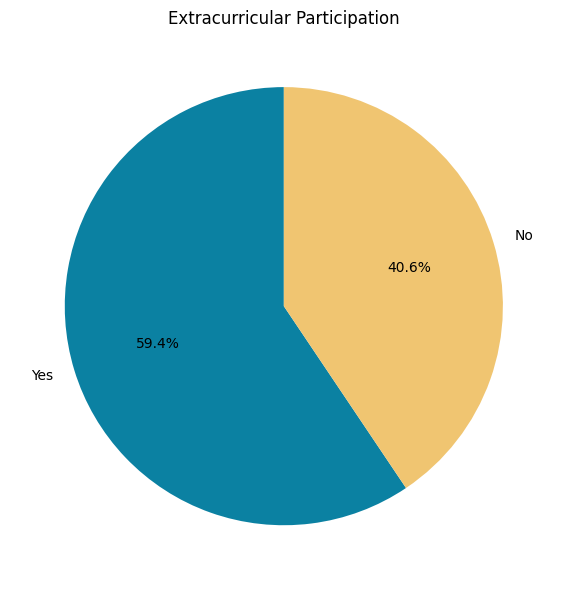

In [ ]:
# 1. Participation in Extracurricular Activities
df_copy = df.copy()
df_copy["Extracurricular_Label"] = df["Extracurricular"].map({0: "No", 1: "Yes"})

# Count each category
counts = df_copy["Extracurricular_Label"].value_counts()

# Plot pie chart
plt.figure(figsize=(6, 6))
plt.pie(
    counts.values,
    labels=counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=['#0b81a2', '#f0c571'],
)
plt.title("Extracurricular Participation")
plt.tight_layout()
plt.show()

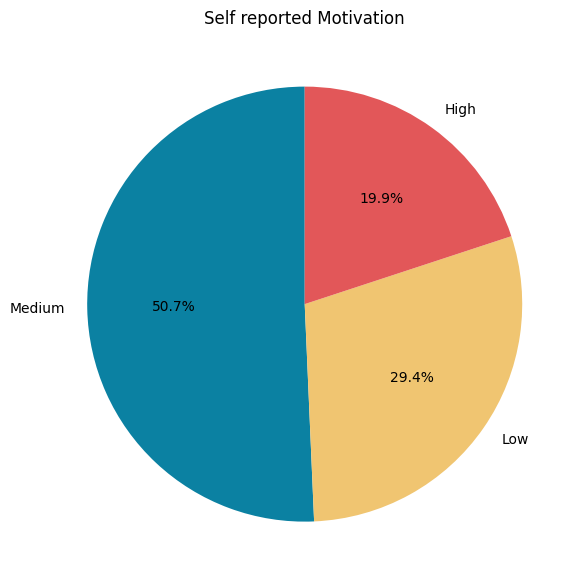

In [ ]:
# 2. Self reported Motivation

df_copy["Motivation_Label"] = df["Motivation"].map({0: "Low", 1: "Medium", 2: "High"})

# Count each category
counts = df_copy["Motivation_Label"].value_counts()

# Plot pie chart
plt.figure(figsize=(6, 6))
plt.pie(
    counts.values,
    labels=counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=['#0b81a2', '#f0c571', '#e25759'],
)
plt.title("Self reported Motivation")
plt.tight_layout()
plt.show()

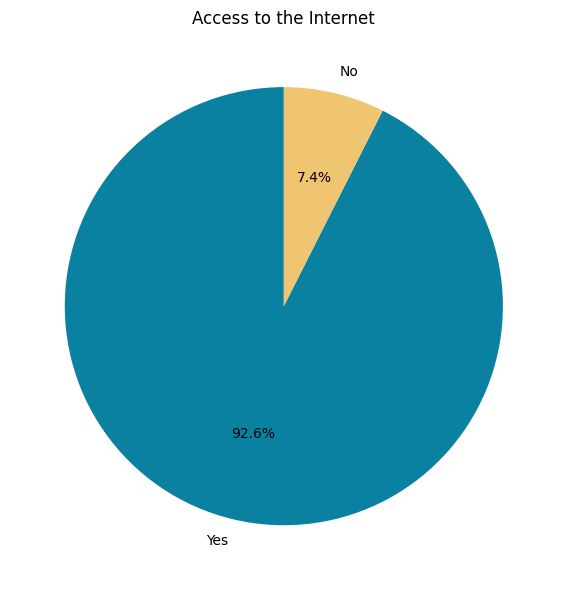

In [ ]:
# 3. Access to the Internet

df_copy["Internet_Label"] = df["Internet"].map({0: "No", 1: "Yes"})

# Count each category
counts = df_copy["Internet_Label"].value_counts()

# Plot pie chart
plt.figure(figsize=(6, 6))
plt.pie(
    counts.values,
    labels=counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=['#0b81a2', '#f0c571'],
)
plt.title("Access to the Internet")
plt.tight_layout()
plt.show()

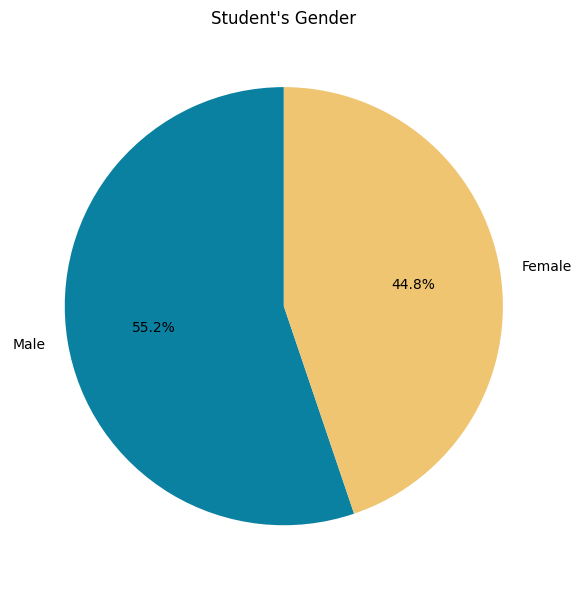

In [ ]:
# 4. Student's Gender

df_copy["Gender_Label"] = df["Gender"].map({1: "Male", 0: "Female"})

# Count each category
counts = df_copy["Gender_Label"].value_counts()

# Plot pie chart
plt.figure(figsize=(6, 6))
plt.pie(
    counts.values,
    labels=counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=['#0b81a2', '#f0c571'],
)
plt.title("Student's Gender")
plt.tight_layout()
plt.show()

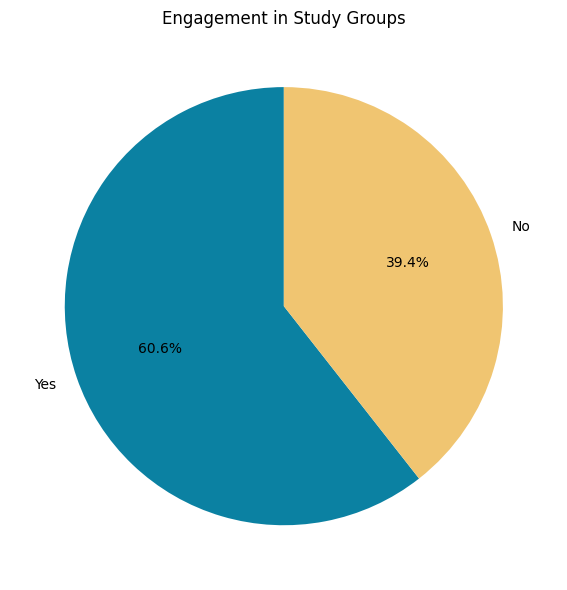

In [ ]:
# 5. Engagement in Study Groups

df_copy["Discussions_Label"] = df["Discussions"].map({0: "No", 1: "Yes"})

# Count each category
counts = df_copy["Discussions_Label"].value_counts()

# Plot pie chart
plt.figure(figsize=(6, 6))
plt.pie(
    counts.values,
    labels=counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=['#0b81a2', '#f0c571'],
)
plt.title("Engagement in Study Groups")
plt.tight_layout()
plt.show()

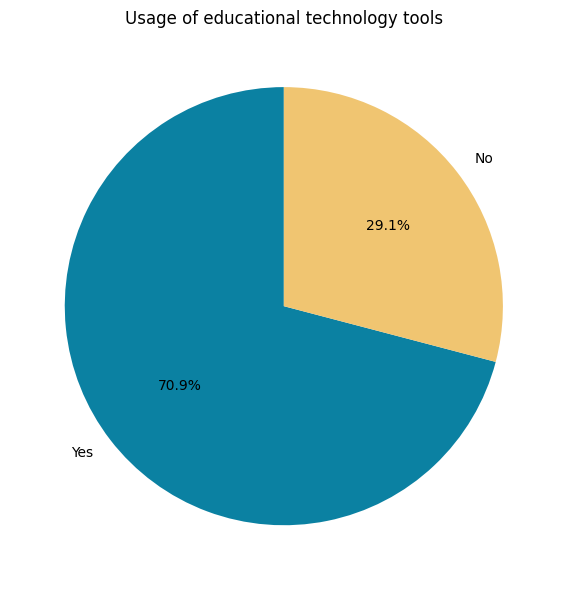

In [ ]:
# 6. Usage of educational technology tools

df_copy["EduTech_Label"] = df["EduTech"].map({0: "No", 1: "Yes"})

# Count each category
counts = df_copy["EduTech_Label"].value_counts()

# Plot pie chart
plt.figure(figsize=(6, 6))
plt.pie(
    counts.values,
    labels=counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=['#0b81a2', '#f0c571'],
)
plt.title("Usage of educational technology tools")
plt.tight_layout()
plt.show()

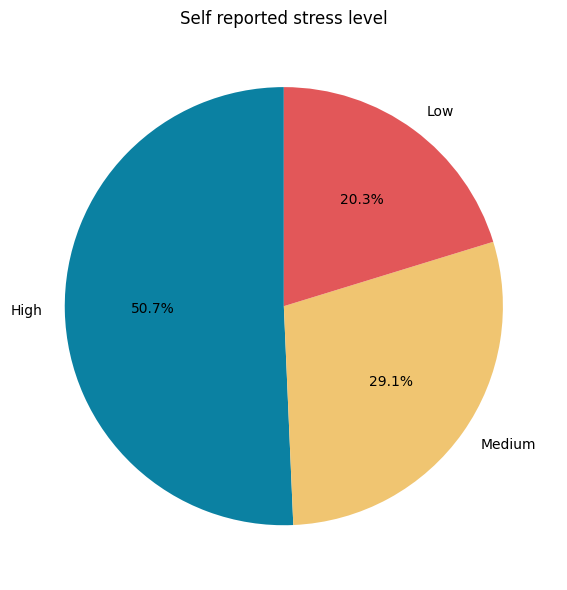

In [ ]:
# 7. Self reported stress level

df_copy["StressLevel_Label"] = df["StressLevel"].map({0: "Low", 1: "Medium", 2: "High"})

# Count each category
counts = df_copy["StressLevel_Label"].value_counts()

# Plot pie chart
plt.figure(figsize=(6, 6))
plt.pie(
    counts.values,
    labels=counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=['#0b81a2', '#f0c571', '#e25759'],
)
plt.title("Self reported stress level")
plt.tight_layout()
plt.show()

# Graphics for Numerical Columns

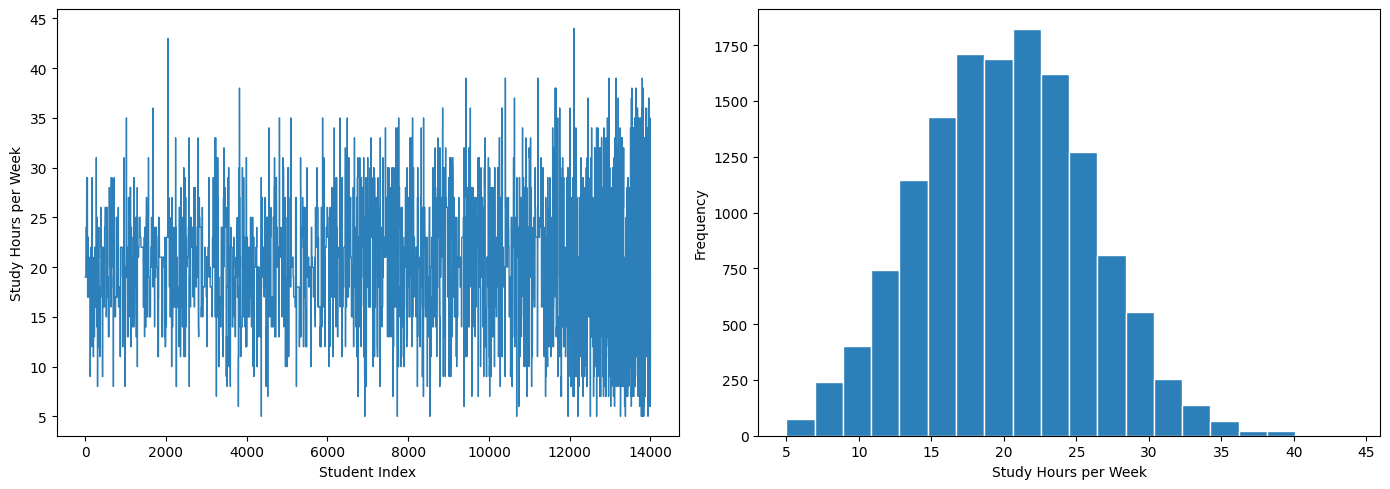

In [ ]:
# 1. Study Hours per week

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Line plot
axes[0].plot(df.index, df["StudyHours"], color="#2c7fb8", linewidth=1)
axes[0].set_xlabel("Student Index")
axes[0].set_ylabel("Study Hours per Week")
# axes[0].set_title("Study Hours Trend")

# Histogram
axes[1].hist(df["StudyHours"], bins=20, color="#2c7fb8", edgecolor="white")
axes[1].set_xlabel("Study Hours per Week")
axes[1].set_ylabel("Frequency")
# axes[1].set_title("Study Hours Distribution")

plt.tight_layout()
plt.show()


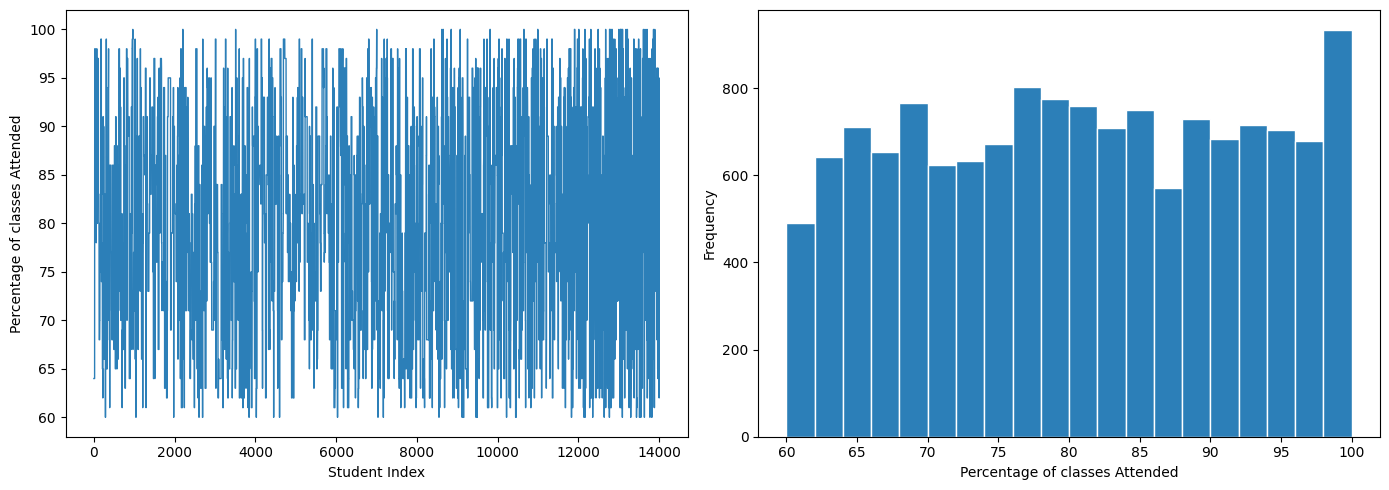

In [ ]:
from matplotlib import lines
# 2. Percentage of classes attended

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Line plot
axes[0].plot(df.index, df["Attendance"], color="#2c7fb8", linewidth=1)
axes[0].set_xlabel("Student Index")
axes[0].set_ylabel("Percentage of classes Attended")
# axes[0].set_title("Study Hours Trend")

# Histogram
axes[1].hist(df["Attendance"], bins=20, color="#2c7fb8", edgecolor="white")
axes[1].set_xlabel("Percentage of classes Attended")
axes[1].set_ylabel("Frequency")
# axes[1].set_title("Study Hours Distribution")

plt.tight_layout()
plt.show()


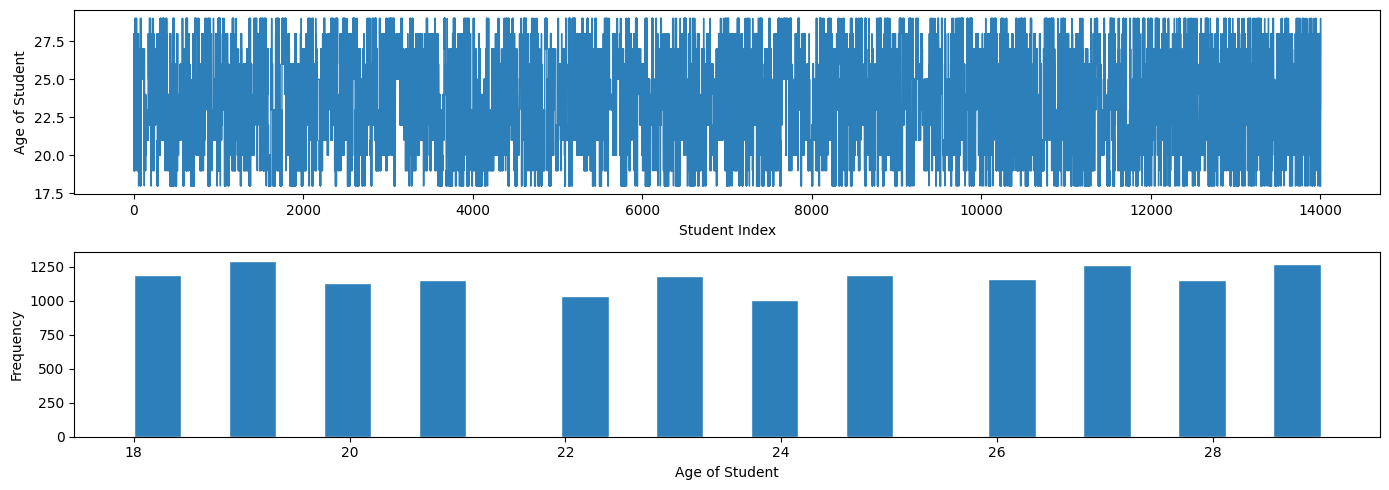

In [ ]:
# 3. Age of student

from matplotlib import lines
# 2. Percentage of classes attended

fig, axes = plt.subplots(2, 1, figsize=(14, 5))

# Line plot
axes[0].plot(df.index, df["Age"], color="#2c7fb8", linewidth=1)
axes[0].set_xlabel("Student Index")
axes[0].set_ylabel("Age of Student")
# axes[0].set_title("Study Hours Trend")

# Histogram
axes[1].hist(df["Age"], bins=25, color="#2c7fb8", edgecolor="white")
axes[1].set_xlabel("Age of Student")
axes[1].set_ylabel("Frequency")
# axes[1].set_title("Study Hours Distribution")

plt.tight_layout()
plt.show()


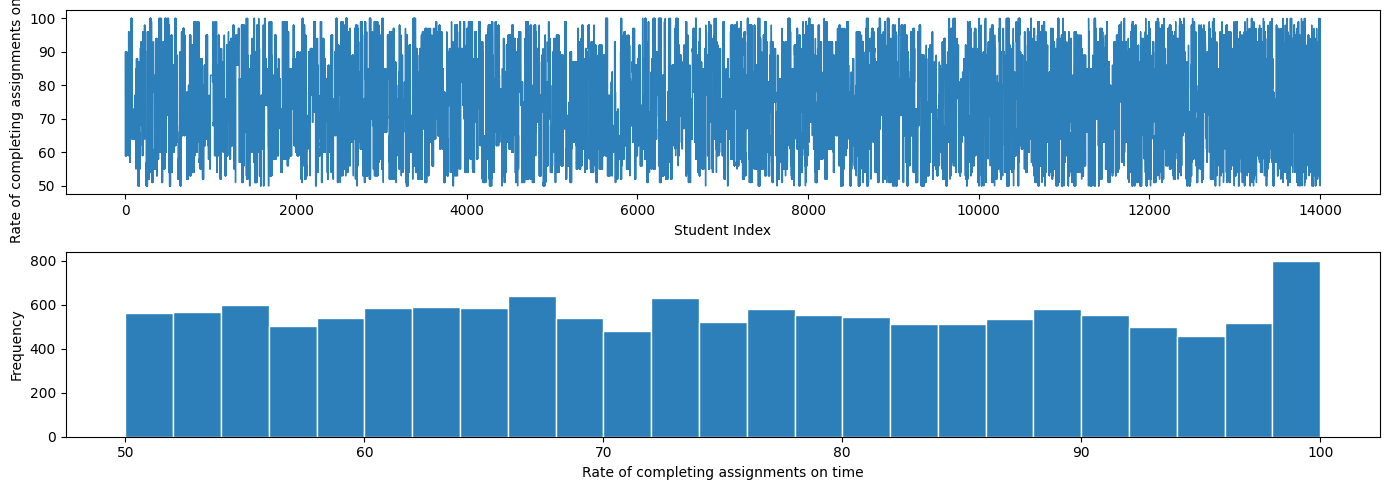

In [ ]:
# 4. Rate of completing assignments on time

fig, axes = plt.subplots(2, 1, figsize=(14, 5))

# Line plot
axes[0].plot(df.index, df["AssignmentCompletion"], color="#2c7fb8", linewidth=1)
axes[0].set_xlabel("Student Index")
axes[0].set_ylabel("Rate of completing assignments on time")
# axes[0].set_title("Study Hours Trend")

# Histogram
axes[1].hist(df["AssignmentCompletion"], bins=25, color="#2c7fb8", edgecolor="white")
axes[1].set_xlabel("Rate of completing assignments on time")
axes[1].set_ylabel("Frequency")
# axes[1].set_title("Study Hours Distribution")

plt.tight_layout()
plt.show()


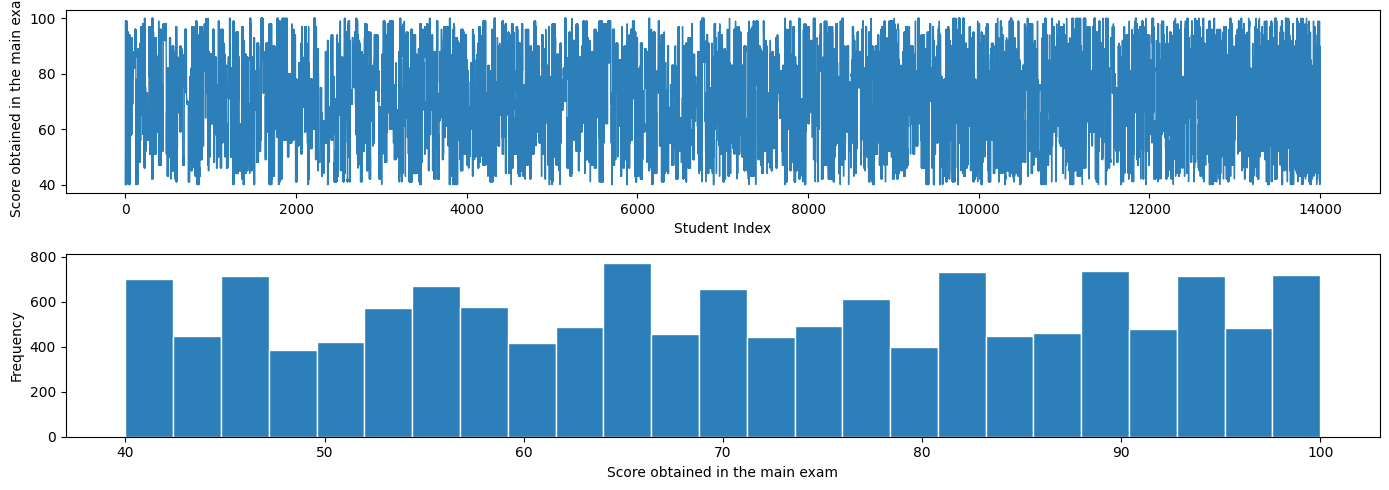

In [ ]:
# 5. Score obtained in the main exam

fig, axes = plt.subplots(2, 1, figsize=(14, 5))

# Line plot
axes[0].plot(df.index, df["ExamScore"], color="#2c7fb8", linewidth=1)
axes[0].set_xlabel("Student Index")
axes[0].set_ylabel("Score obtained in the main exam")
# axes[0].set_title("Study Hours Trend")

# Histogram
axes[1].hist(df["ExamScore"], bins=25, color="#2c7fb8", edgecolor="white")
axes[1].set_xlabel("Score obtained in the main exam")
axes[1].set_ylabel("Frequency")
# axes[1].set_title("Study Hours Distribution")

plt.tight_layout()
plt.show()


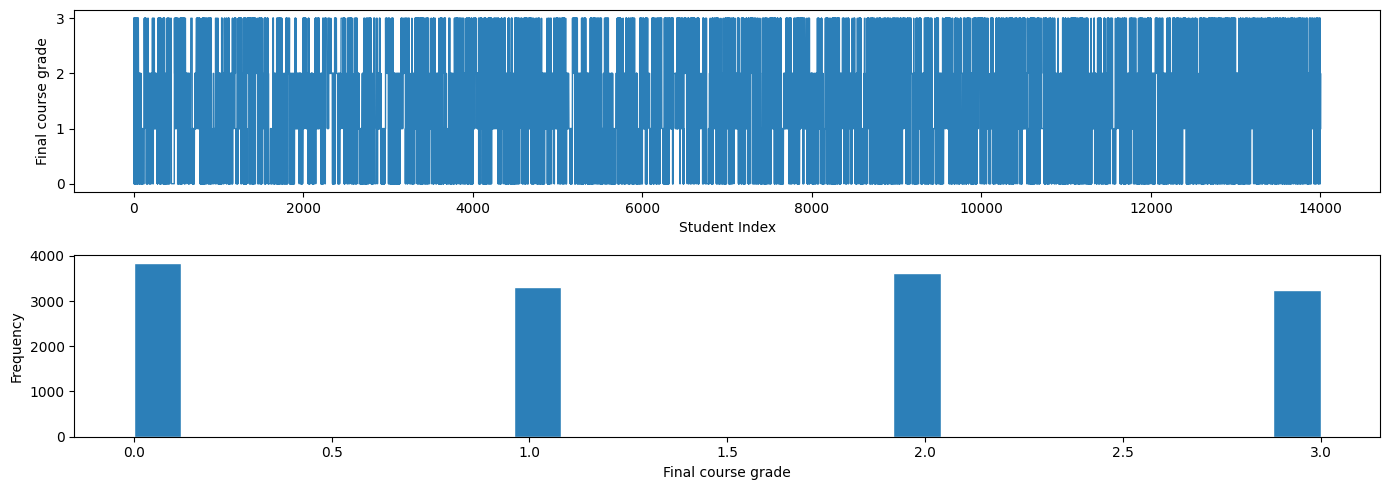

In [ ]:
# 6. Final course grade

fig, axes = plt.subplots(2, 1, figsize=(14, 5))

# Line plot
axes[0].plot(df.index, df["FinalGrade"], color="#2c7fb8", linewidth=1)
axes[0].set_xlabel("Student Index")
axes[0].set_ylabel("Final course grade")
# axes[0].set_title("Study Hours Trend")

# Histogram
axes[1].hist(df["FinalGrade"], bins=25, color="#2c7fb8", edgecolor="white")
axes[1].set_xlabel("Final course grade")
axes[1].set_ylabel("Frequency")
# axes[1].set_title("Study Hours Distribution")

plt.tight_layout()
plt.show()

# Tarea a Realizar:

1. Utilizar regresión para predecir el promedio obtenido al final del curso.
2. Convertir el puntaje del curso en categorías ("Bajo", "Medio", "Alto") para utilizar clasificación.

# Segunda Parte



### Limpieza

In [ ]:
# Valores nulos
df.isnull().sum()

,0
StudyHours,0
Attendance,0
Resources,0
Extracurricular,0
Motivation,0
Internet,0
Gender,0
Age,0
LearningStyle,0
Discussions,0


In [ ]:
df.duplicated().sum()

np.int64(1534)

In [ ]:
df_clean = df.drop_duplicates().reset_index(drop=True)

### Librerias y Particionado

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
print(df["FinalGrade"].value_counts().sort_index())

mapa = {0: 0, 1: 1, 2: 1, 3: 2}
nombres = ["Bajo", "Medio", "Alto"]

y = df["FinalGrade"].map(mapa)
X = df.drop(columns=["FinalGrade", "ExamScore"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

y_clean = df_clean["FinalGrade"].map(mapa)
X_clean = df_clean.drop(columns=["FinalGrade", "ExamScore"])

X_train_clean, X_test_clean, y_train_clean, y_test_clean = train_test_split(
    X_clean, y_clean, test_size=0.2, random_state=42
)

print(y_clean)

FinalGrade
0    3832
1    3310
2    3618
3    3243
Name: count, dtype: int64
0        2
1        1
2        0
3        2
4        1
        ..
12464    1
12465    1
12466    1
12467    1
12468    1
Name: FinalGrade, Length: 12469, dtype: int64


### DecisionTree

depth=1     train=0.496 val=0.487
depth=2     train=0.496 val=0.487
depth=3     train=0.496 val=0.487
depth=4     train=0.505 val=0.505
depth=5     train=0.515 val=0.505
depth=6     train=0.531 val=0.521
depth=7     train=0.564 val=0.539
depth=8     train=0.599 val=0.548
depth=9     train=0.652 val=0.571
depth=10    train=0.710 val=0.639
depth=11    train=0.773 val=0.678
depth=12    train=0.835 val=0.741
depth=13    train=0.886 val=0.782
depth=14    train=0.930 val=0.828
depth=15    train=0.954 val=0.850
depth=16    train=0.971 val=0.867
depth=17    train=0.982 val=0.875
depth=18    train=0.990 val=0.884
depth=19    train=0.994 val=0.891
depth=20    train=0.997 val=0.892
depth=21    train=0.999 val=0.895
depth=22    train=1.000 val=0.894
depth=23    train=1.000 val=0.898
depth=24    train=1.000 val=0.898
depth=25    train=1.000 val=0.898
depth=26    train=1.000 val=0.898
depth=27    train=1.000 val=0.898
depth=28    train=1.000 val=0.898
depth=29    train=1.000 val=0.898
depth=30    tr

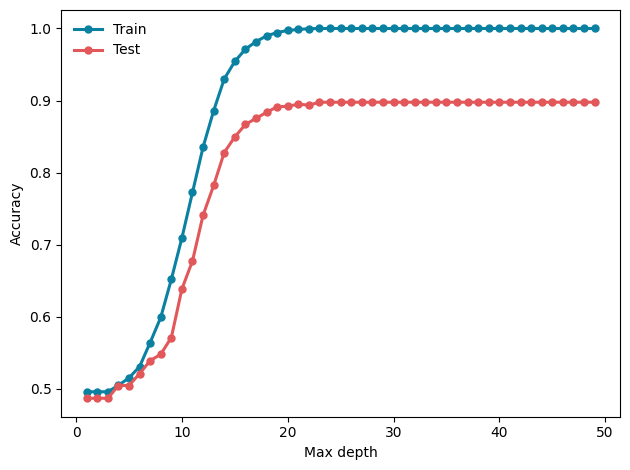

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

def show_curve_MaxDepth(est, depth1, depth2):
    maxDepth_range = range(depth1, depth2)
    train_acc, test_acc = [], []

    for depth in maxDepth_range:
        clf = est(max_depth=depth, random_state=42)
        clf.fit(X_train_clean, y_train_clean)

        train_acc.append(accuracy_score(y_train_clean, clf.predict(X_train_clean)))
        test_acc.append(accuracy_score(y_test_clean, clf.predict(X_test_clean)))

        print(f"depth={depth:<5} train={train_acc[-1]:.3f} val={test_acc[-1]:.3f}")

    fig, ax = plt.subplots()

    ax.plot(maxDepth_range, train_acc, color="#0b81a2", linewidth=2.2,
            marker="o", markersize=5, label="Train")
    ax.plot(maxDepth_range, test_acc, color="#e25759", linewidth=2.2,
            marker="o", markersize=5, label="Test")

    ax.set_xlabel("Max depth")
    ax.set_ylabel("Accuracy")
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.show()


show_curve_MaxDepth(DecisionTreeClassifier, 1, 50)

In [ ]:
est = DecisionTreeClassifier(max_depth= 20)
est.fit(X_train_clean, y_train_clean)
est.feature_importances_

array([0.21148576, 0.19317471, 0.00844221, 0.00317034, 0.0052461 ,
       0.00266566, 0.04529993, 0.12611222, 0.09170882, 0.0327678 ,
       0.19585142, 0.02892012, 0.05515492])

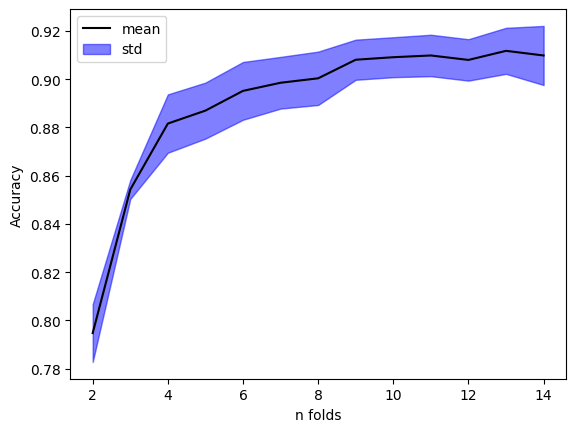

In [ ]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.tree import DecisionTreeClassifier

def show_curve_KFold(est):
    means, stds = [], []
    nfolds_range = range(2, 15)

    for nfolds in nfolds_range:
        s = cross_val_score(est, X_clean, y_clean, cv=KFold(nfolds, shuffle=True), scoring="accuracy")
        means.append(np.mean(s))
        stds.append(np.std(s))

    means = np.array(means)
    stds = np.array(stds)

    plt.plot(nfolds_range, means, label="mean", color="black")
    plt.fill_between(nfolds_range, means - stds, means + stds,
                     color="blue", alpha=.5, label="std")
    plt.xlabel("n folds")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.show()

show_curve_KFold(DecisionTreeClassifier(max_depth= 20))


### Random Forest

estimators=1     train=0.825 val=0.521
estimators=2     train=0.838 val=0.553
estimators=3     train=0.940 val=0.671
estimators=4     train=0.953 val=0.694
estimators=5     train=0.977 val=0.733
estimators=6     train=0.982 val=0.743
estimators=7     train=0.987 val=0.755
estimators=8     train=0.992 val=0.771
estimators=9     train=0.994 val=0.791
estimators=10    train=0.996 val=0.810
estimators=11    train=0.997 val=0.812
estimators=12    train=0.998 val=0.825
estimators=13    train=0.998 val=0.829
estimators=14    train=0.999 val=0.836
estimators=15    train=0.999 val=0.839
estimators=16    train=0.999 val=0.848
estimators=17    train=0.999 val=0.849
estimators=18    train=0.999 val=0.854
estimators=19    train=0.999 val=0.856
estimators=20    train=1.000 val=0.860
estimators=21    train=1.000 val=0.860
estimators=22    train=1.000 val=0.865
estimators=23    train=1.000 val=0.868
estimators=24    train=1.000 val=0.867
estimators=25    train=1.000 val=0.871
estimators=26    train=1.

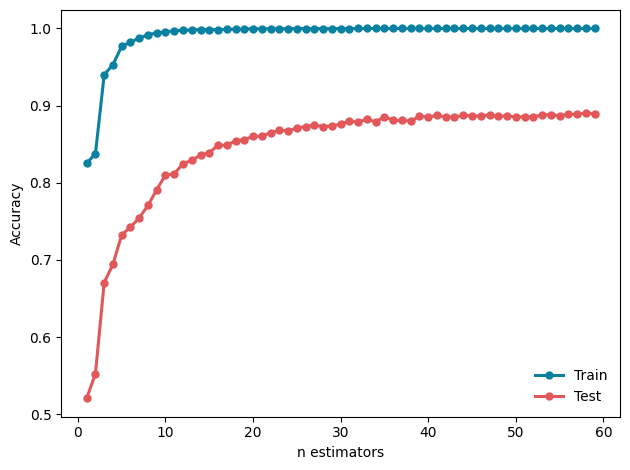

In [ ]:
from sklearn.ensemble import RandomForestClassifier

def show_curve_nestimators(est, n1, n2):
    ns = range(n1,n2)
    train_acc, test_acc = [], []

    for n in ns:
        clf = est(n_estimators=n, random_state=42)
        clf.fit(X_train_clean, y_train_clean)

        train_acc.append(accuracy_score(y_train_clean, clf.predict(X_train_clean)))
        test_acc.append(accuracy_score(y_test_clean, clf.predict(X_test_clean)))

        print(f"estimators={n:<5} train={train_acc[-1]:.3f} val={test_acc[-1]:.3f}")


    fig, ax = plt.subplots()

    ax.plot(ns, train_acc, color="#0b81a2", linewidth=2.2,
            marker="o", markersize=5, label="Train")
    ax.plot(ns, test_acc, color="#e25759", linewidth=2.2,
            marker="o", markersize=5, label="Test")

    ax.set_xlabel("n estimators")
    ax.set_ylabel("Accuracy")
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.show()

show_curve_nestimators(RandomForestClassifier, 1, 60)

In [ ]:
est = RandomForestClassifier(n_estimators = 50)
est.fit(X_train_clean, y_train_clean)
est.feature_importances_

array([0.17104402, 0.17951248, 0.03693694, 0.0219867 , 0.03787269,
       0.0105947 , 0.03408923, 0.12913024, 0.07217917, 0.0328994 ,
       0.1930522 , 0.03253411, 0.04816811])

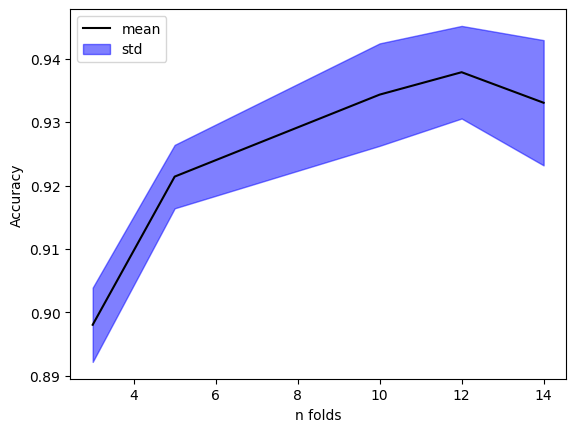

In [ ]:
show_curve_KFold(RandomForestClassifier(n_estimators= 40))

### SVM

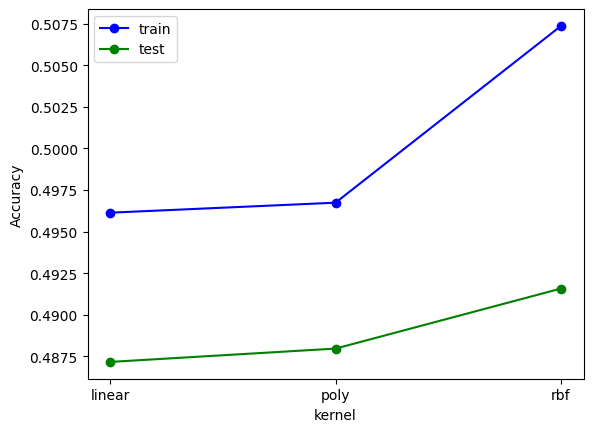

In [ ]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, KFold



def show_curve_kernel():
    kernels = ["linear", "poly", "rbf"]
    train_acc, test_acc = [], []

    for k in kernels:
         clf = make_pipeline(
            StandardScaler(),
            SVC(kernel=k, random_state=42)
        )
         clf.fit(X_train_clean, y_train_clean)

         train_acc.append(accuracy_score(y_train_clean, clf.predict(X_train_clean)))
         test_acc.append(accuracy_score(y_test_clean, clf.predict(X_test_clean)))

    plt.plot(kernels, train_acc, marker="o", color="blue", label="train")
    plt.plot(kernels, test_acc, marker="o", color="green", label="test")
    plt.xlabel("kernel")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.show()

show_curve_kernel()

gamma=0.1   train=0.498 val=0.491 (41s)
gamma=1     train=0.835 val=0.700 (21s)
gamma=3     train=0.998 val=0.882 (8s)
gamma=10    train=0.999 val=0.894 (4s)
gamma=30    train=0.999 val=0.899 (6s)
gamma=100   train=0.999 val=0.901 (6s)


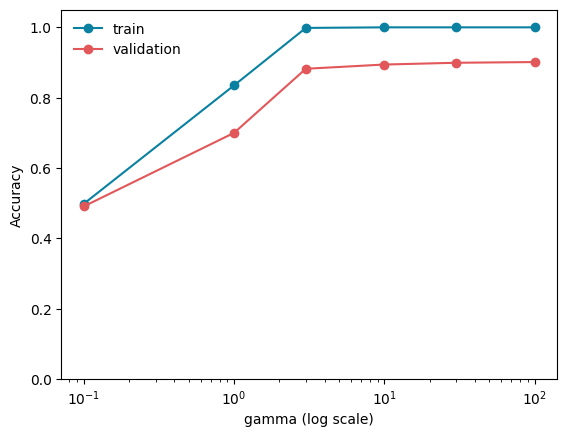

best gamma: 100 | train: 0.999 | test: 0.935


In [ ]:
import time
from sklearn.model_selection import train_test_split

cols = ["StudyHours", "Attendance", "AssignmentCompletion", "Age"]

Xa, Xv, ya, yv = train_test_split(
    X_train_clean[cols], y_train_clean,
    test_size=0.2, random_state=42
)

gammas = [0.1, 1, 3, 10, 30, 100]
train_acc, val_acc = [], []

for g in gammas:
    t = time.time()
    clf = make_pipeline(
            StandardScaler(),
            SVC(kernel="rbf", C=100, gamma=g, cache_size=1000, random_state=42)
        )
    clf.fit(Xa, ya)
    train_acc.append(clf.score(Xa, ya))
    val_acc.append(clf.score(Xv, yv))
    print(f"gamma={g:<5} train={train_acc[-1]:.3f} val={val_acc[-1]:.3f} ({time.time()-t:.0f}s)")

plt.plot(gammas, train_acc, marker="o", color="#0b81a2", label="train")
plt.plot(gammas, val_acc, marker="o", color="#e25759", label="validation")
plt.xscale("log")
plt.xlabel("gamma")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.legend(frameon=False)
plt.show()

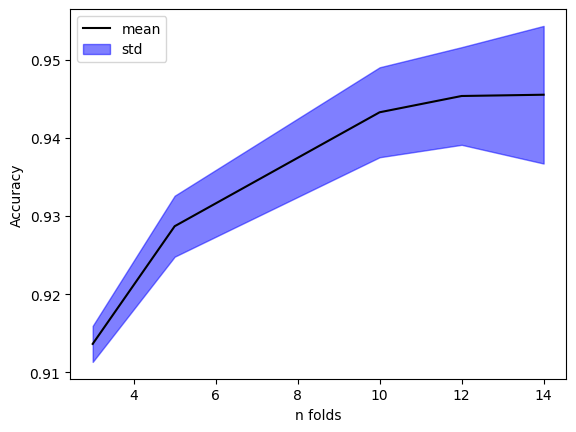

In [ ]:
def show_curve_KFold(est):
    means, stds = [], []
    nfolds_range = [3,5,10,12, 14]

    for nfolds in nfolds_range:
        s = cross_val_score(est, X_clean[cols], y_clean, cv=KFold(nfolds, shuffle=True), scoring="accuracy",  n_jobs=-1)
        means.append(np.mean(s))
        stds.append(np.std(s))

    means = np.array(means)
    stds = np.array(stds)

    plt.plot(nfolds_range, means, label="mean", color="black")
    plt.fill_between(nfolds_range, means - stds, means + stds,
                     color="blue", alpha=.5, label="std")
    plt.xlabel("n folds")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.show()

est = make_pipeline(StandardScaler(), SVC(kernel="rbf", gamma = 100, C = 100, cache_size=1000, random_state=42))
show_curve_KFold(est)


### Deep Learning

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error


arquitecturas = {
    "3 capas (64,128,128)": [64, 128, 128],
    "6 capas (64,64,128,128,256,256)": [64, 64, 128, 128, 256, 256],
    "10 capas (10x128)": [128] * 10,
}
num_epochs = [5, 10, 50, 100]



n_features = X_train_clean.shape[1]
n_classes = len(np.unique(y_train_clean))

def crear_modelo(capas, n_features, n_classes):
    tf.keras.backend.clear_session()
    model = keras.Sequential([keras.layers.Input(shape=(n_features,))])
    for u in capas:
        model.add(keras.layers.Dense(u, activation="relu"))
    model.add(keras.layers.Dense(n_classes, activation="softmax"))
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

scaler = StandardScaler()
Xtr = scaler.fit_transform(X_train_clean)
Xte = scaler.transform(X_test_clean)

rows = []
for nombre, capas in arquitecturas.items():
    for ep in num_epochs:
        model = crear_modelo(capas, n_features, n_classes)
        model.fit(Xtr, y_train_clean, epochs=ep, batch_size=64, verbose=0)
        tr = model.evaluate(Xtr, y_train_clean, verbose=0)[1]
        te = model.evaluate(Xte, y_test_clean, verbose=0)[1]
        rows.append({"arquitectura": nombre, "epochs": ep, "train_acc": tr, "test_acc": te})
        print(f"{nombre:35s} epochs={ep:<4} train={tr:.3f} test={te:.3f}")

df_dl = pd.DataFrame(rows)
print(df_dl.pivot(index="arquitectura", columns="epochs", values="test_acc"))

3 capas (64,128,128)                epochs=5    train=0.540 test=0.482
3 capas (64,128,128)                epochs=10   train=0.603 test=0.500
3 capas (64,128,128)                epochs=50   train=0.970 test=0.708
3 capas (64,128,128)                epochs=100  train=0.965 test=0.697
6 capas (64,64,128,128,256,256)     epochs=5    train=0.548 test=0.483
6 capas (64,64,128,128,256,256)     epochs=10   train=0.699 test=0.548
6 capas (64,64,128,128,256,256)     epochs=50   train=0.973 test=0.737
6 capas (64,64,128,128,256,256)     epochs=100  train=0.993 test=0.672
10 capas (10x128)                   epochs=5    train=0.499 test=0.487
10 capas (10x128)                   epochs=10   train=0.595 test=0.496
10 capas (10x128)                   epochs=50   train=0.980 test=0.774
10 capas (10x128)                   epochs=100  train=0.994 test=0.810
epochs                                5         10        50        100
arquitectura                                                           
10 c

### Resultado

                       Train   Test
Modelo                             
DT (depth=23)          1.000  0.894
RF (40 estimators)     1.000  0.904
SVM (rbf)              0.999  0.935
DL (10 capas, 100 ep)  0.994  0.810


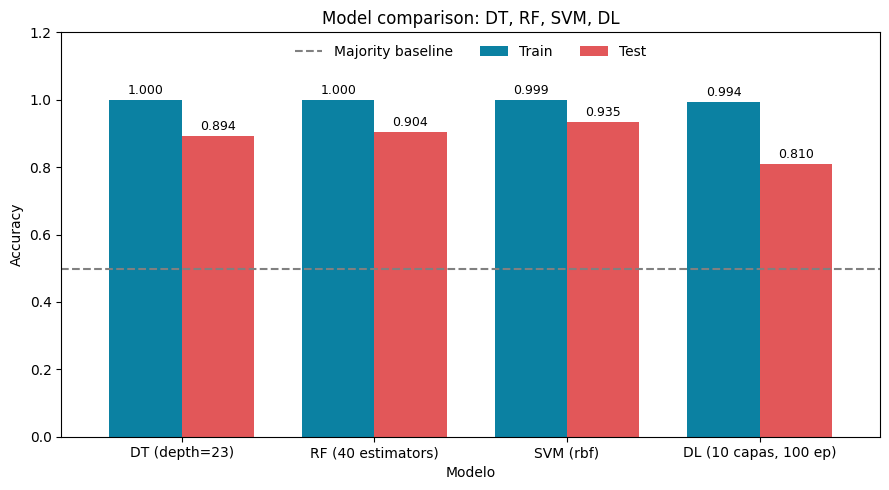

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

modelos = {
    "DT (depth=23)": DecisionTreeClassifier(max_depth=22, random_state=42),
    "RF (40 estimators)": RandomForestClassifier(n_estimators=100, random_state=42),
}

resultados = []
for nombre, m in modelos.items():

  m.fit(X_train_clean, y_train_clean)
  resultados.append({
      "Modelo": nombre,
      "Train": accuracy_score(y_train_clean, m.predict(X_train_clean)),
      "Test": accuracy_score(y_test_clean, m.predict(X_test_clean)),
  })

clf_svc = make_pipeline(StandardScaler(), SVC(kernel="rbf", gamma = 100, C = 100, cache_size=1000, random_state=42))
clf_svc.fit(X_train_clean[cols], y_train_clean)
resultados.append(
    {"Modelo": "SVM (rbf)",
     "Train": accuracy_score(y_train_clean, clf_svc.predict(X_train_clean[cols])),
     "Test": accuracy_score(y_test_clean, clf_svc.predict(X_test_clean[cols]))
     })


# DL: best configuration from df_dl
b = df_dl.loc[df_dl["test_acc"].idxmax()]
resultados.append({
    "Modelo": f"DL ({b['arquitectura'].split(' (')[0]}, {int(b['epochs'])} ep)",
    "Train": b["train_acc"],
    "Test": b["test_acc"],
})

df_final = pd.DataFrame(resultados).set_index("Modelo")
print(df_final.round(3))

ax = df_final.plot(kind="bar", figsize=(9, 5), color=["#0b81a2", "#e25759"], width=0.75)
ax.axhline(y_train.value_counts(normalize=True).max(), color="gray",
           linestyle="--", label="Majority baseline")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=9, padding=2)

ax.set_ylim(0, 1.2)
ax.set_ylabel("Accuracy")
ax.set_title("Model comparison: DT, RF, SVM, DL")
plt.xticks(rotation=0)
ax.legend(frameon=False, loc="upper center", ncol=3)
plt.tight_layout()
plt.show()

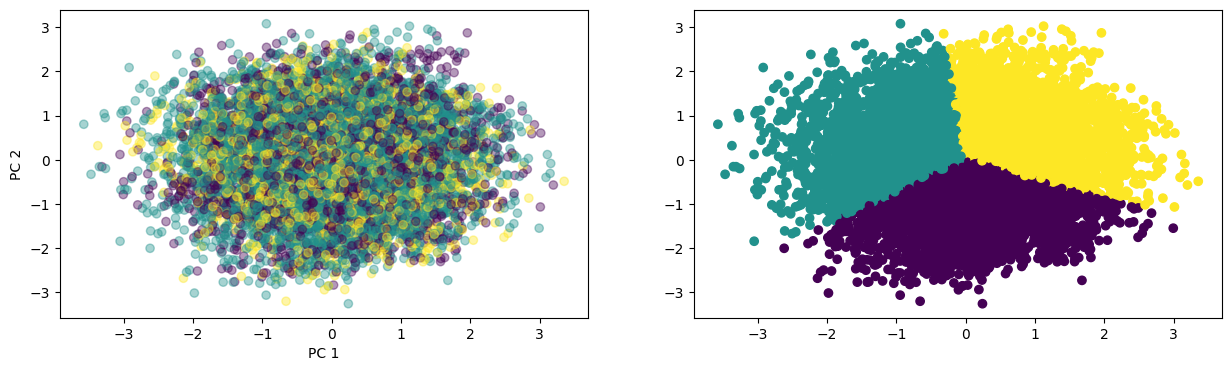

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
import matplotlib.pyplot as plt

n_clases = 3

# 1) Escalar
X_scaled = StandardScaler().fit_transform(X_train_clean)

# 2) PCA a 2 componentes
X_pca = PCA(n_components=2).fit_transform(X_scaled)

# 3) K-Means
km = KMeans(n_clusters=n_clases, random_state=42).fit(X_pca)

# 5) Gráficas
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].scatter(X_pca[:,0], X_pca[:,1], c=y_train_clean, alpha=0.4)
ax[0].set_xlabel("PC 1"); ax[0].set_ylabel("PC 2")
ax[1].scatter(X_pca[:,0], X_pca[:,1], c=km.labels_)
plt.show()

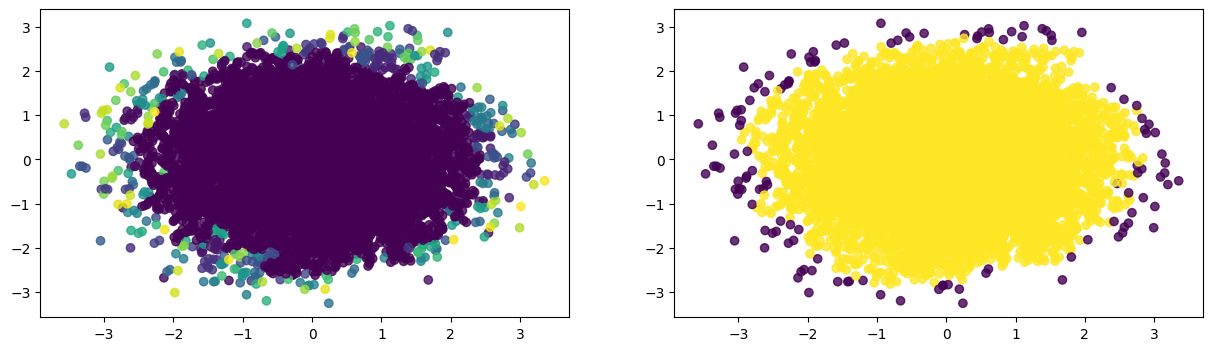

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
import matplotlib.pyplot as plt

n_clases = 3

# 1) Escalar
X_scaled = StandardScaler().fit_transform(X_train_clean)

# 2) PCA a 2 componentes
X_pca = PCA(n_components=2).fit_transform(X_scaled)

# 4) DBSCAN (ajusta eps y min_samples)
db1 = DBSCAN(eps=0.1, min_samples=1).fit(X_pca)
db2 = DBSCAN(eps=0.2, min_samples=7).fit(X_pca)

# 5) Gráficas
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].scatter(X_pca[:,0], X_pca[:,1], c=db1.labels_, alpha=0.8)
ax[1].scatter(X_pca[:,0], X_pca[:,1], c=db2.labels_, alpha=0.8)
plt.show()

Al mirar la distribución de los valores resulta evidente lo díficil que puede ser clasificar correctamente utilizando el método DBSCAN.

Debido a cómo funciona este método pueden ocurrir dos cosas:

Debido a la gran concentración de valores en el centro, no importa qué tan bajo sea un valor de epsilon, el modelo va a seguir recorriendo y clasificando a esa gran "mancha" como una única clase.

1. Con un valor bajo de epsilon y un min_samples de 1: Los puntos de alrededor se clasifican uno por uno en clases distintas.

2. Con un valor un poco más alto para epsilon y un min_samples de 7: Los puntos de alrededor (que siguen un camino) son recorridos por completo sin cambios de clase.

